## 1 · Instalar y bajar los 3 archivos  ·  *al terminar, reinicia el entorno de ejecución*

Baja `oraculo.py`, `ayudas.py` y `datos_visibles.json`, más las librerías que usan el modelo y los verificadores. El reinicio es obligatorio: si siguen sin reiniciar, `transformers` a veces queda a medias y `cargar_modelo` falla con un error opaco.

In [8]:
# bitsandbytes: checkpoints 4-bit (qwen8b, mistral7b). nltk/spacy/emoji/langdetect:
# los usa el verificador de open-instruct, no el notebook.
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q
!git clone -q https://github.com/allenai/open-instruct

REPO = "https://raw.githubusercontent.com/DanielMelo404/Proyecto-Oraculo-AyD/main"
# --no-cache: Colab a veces reusa un ayudas.py viejo y el alias no existe.
!wget -q --no-cache -O oraculo.py {REPO}/oraculo.py
!wget -q --no-cache -O ayudas.py {REPO}/ayudas.py
!wget -q --no-cache -O datos_visibles.json {REPO}/datos_visibles.json

# Los datos de nltk se bajan a mano: su downloader rechaza el proxy de Colab.
import io
import urllib.request
import zipfile

NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
PAQUETES = [
    ("tokenizers", "punkt"),
    ("tokenizers", "punkt_tab"),
    ("taggers", "averaged_perceptron_tagger"),
    ("taggers", "averaged_perceptron_tagger_eng"),
]
for carpeta, nombre in PAQUETES:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
fatal: destination path 'open-instruct' already exists and is not an empty directory.
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · El modelo

Antes: **Entorno de ejecución ▸ Cambiar tipo de entorno de ejecución ▸ T4 GPU**.
Sin GPU, `cargar_modelo` no arranca.

`cargar_modelo` acepta un alias de la tabla o cualquier id público de Hugging Face (`org/nombre`).
El por defecto es `qwen17b` (`Qwen/Qwen3-1.7B`), el más rápido para T4.

In [1]:
from ayudas import cargar_modelo

# Alias → checkpoint. El nombre entra en la clave de caché: si cambian de
# modelo, las respuestas anteriores no se reusan.
modelo = cargar_modelo("qwen17b")

cargando qwen17b → Qwen/Qwen3-1.7B


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Qwen/Qwen3-1.7B  VRAM: 3.44 GB


## 3 · El oráculo

`dividir` parte `datos_visibles.json` en búsqueda (100) y validación (87). Busquen solo sobre `busqueda`. `validar` mide la config ya elegida sobre instancias que no se usaron al buscar.

Si Colab se desconecta, descomenten las dos líneas de Drive para no perder el caché.

In [2]:
# Descomenten estas dos líneas si quieren que el caché sobreviva a una
# desconexión: el path de Drive reemplaza cache_oraculo.json local.
from google.colab import drive
drive.mount("/content/drive")

from oraculo import Oraculo, CATALOGO, RANURAS, TEMPERATURAS, espacio
from ayudas import cargar_datos, dividir

datos = cargar_datos()
busqueda, validacion = dividir(datos)
# 1.7B en fp16 deja VRAM en la T4: un lote más grande genera más prompts a la vez.
oraculo = Oraculo(modelo, busqueda, validacion, lote=16, presupuesto=32_000_000)
# oraculo = Oraculo(modelo, busqueda, validacion, cache="/content/drive/MyDrive/oraculo_cache.json", lote=16, presupuesto=32_000_000)

# 32768 configs con temperatura 0.0
CONFIGS = espacio()
print(len(CONFIGS), "configuraciones posibles")

Mounted at /content/drive
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
caché: 380 respuestas recuperadas
32768 configuraciones posibles


## 4 · Backtracking con Poda por Abandono Temprano (Cota por Instancia)

### 1. Método y Estructura del Árbol de Decisión
- **Espacio de Búsqueda:** $8^5 = 32\,768$ configuraciones con temperatura fija en `0.0` (decodificación greedy determinista).
- **Árbol:** Profundidad 5 (un nivel por ranura), factor de ramificación 8. Cada hoja representa una configuración completa candidata.
- **Incumbente Inicial:** Sin configuraciones *ad-hoc* ni suposiciones teóricas. La **primera hoja evaluada** por el recorrido del árbol establece el incumbente inicial $mejor = (p_0, C_0)$.

### 2. Cota Rigurosa por Instancia (Abandono Temprano)
- Al evaluar una hoja sobre las $n = 100$ instancias de `busqueda`, la inferencia se ejecuta en lotes de tamaño `tam_lote` (16, coincidente con `oraculo.lote`).
- Tras evaluar $k$ instancias con $c$ aciertos acumulados, las $n - k$ instancias restantes pueden a lo sumo resultar todas correctas (evaluación todo-o-nada).
- La precisión máxima alcanzable por esta hoja es estrictamente:
$$
\text{CotaSuperior}(C \mid k) = \frac{c + (n - k)}{n}
$$
- **Regla de Poda:** Si $\text{CotaSuperior}(C \mid k) \le mejor[0]$, la configuración **no puede superar al incumbente** y se **abandona de inmediato**, ahorrando el cómputo en GPU de las $n - k$ instancias restantes.
- **Qué garantiza:** Admisibilidad matemática estricta sobre el lote de búsqueda. Ninguna hoja podada por esta cota podría haber superado al incumbente.
- **Qué NO garantiza:** Con presupuesto limitado $B \ll 32\,768$, no garantiza encontrar el óptimo global del espacio (la búsqueda se trunca por presupuesto antes de recorrer el árbol entero).

### 3. Cota a Nivel de Nodo Interno (Heurística)
- En un modelo de lenguaje de caja negra no existe una cota superior admisible a nivel de nodo interno sin supuestos no verificables. Se incluye la bandera `USAR_PODA_INTERNA_HEURISTICA = False` (desactivada por defecto para preservar rigor analítico).

### 4. Orden de Ranuras y Opciones Derivado de Datos Reales
A partir de las trazas de fallos medidas en Colab (84 fallos en ~40 familias) y las 36 evaluaciones registradas en T4:
1. **Orden de Ranuras:** `['cierre', 'formato', 'estilo', 'estrategia', 'rol']`.
   - *Evidencia:* `cierre` gobierna la restricción más frecuente en trazas (`last_word:last_word_sent`, 8 fallos), y `formato` gobierna las restricciones estructurales (`paragraphs`, `square_brackets`, `multiple_sections`, 13 fallos acumulados). Colocarlas en los primeros niveles maximiza el descarte temprano.
2. **Orden de Opciones:** Dentro de cada ranura se exploran primero las opciones que no fuerzan texto espurio ni destruyen puntuación:
   - `cierre`: `[3, 6, 2, 7, 5, 4, 1, 0]` (opción 3 inyecta `{restricciones}`; opciones 0, 1 y 4 agregan sufijos letales).
   - `formato`: `[0, 4, 6, 2, 1, 7, 3, 5]` (opción 0 no añade preámbulos; opciones 3 y 5 fuerzan viñetas y encabezados).
   - `estilo`: `[6, 2, 0, 3, 4, 1, 5, 7]` (opción 6 respeta caracteres; opciones 1 y 4 alteran mayúsculas/puntuación).
   - `estrategia`: `[2, 1, 5, 4, 6, 7, 0, 3]` (opción 2 no infla texto; opciones 0 y 3 violan límites de longitud).
   - `rol`: `[5, 2, 3, 0, 1, 4, 6, 7]` (opción 5 es concisa; opciones 0 y 7 agregan saludos fijos en prefijo).

### 5. Presupuesto y Condición de Parada
- `B_CONSULTAS = 12` configuraciones evaluadas (~45 min en T4 a ~207 s/config).
- **Parada:** Por árbol agotado (`COMPLETA`, requiere $B \ge 32\,768$) o por presupuesto agotado (`TRUNCADA`, resultado esperado para $B=12$, sin garantía de optimalidad global).
- **Reanudable:** Aprovecha el caché persistente del oráculo. Las instancias ya evaluadas se recuperan en 0.0 s sin volver a generar tokens en GPU.

=== INICIANDO BACKTRACKING CON PODA POR ABANDONO TEMPRANO ===
Espacio: 32 768 configs | B_CONSULTAS = 36 configs | Lote = 16 inst

eval  1/36 | NUEVO MEJOR: 16.0% (100/100 inst) |   0.0s | {'cierre': 3, 'formato': 0, 'estilo': 6, 'estrategia': 2, 'rol': 5, 'temperatura': 0.0}
eval  2/36 | evaluada:    14.0% (100/100 inst) |   0.0s
eval  3/36 | evaluada:    15.0% (100/100 inst) |   0.0s


evaluando:   0%|          | 0/16 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/4 [00:00<?, ?inst/s]

eval  4/36 | NUEVO MEJOR: 18.0% (100/100 inst) |  59.0s | {'cierre': 3, 'formato': 0, 'estilo': 6, 'estrategia': 2, 'rol': 0, 'temperatura': 0.0}


evaluando:   0%|          | 0/16 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/16 [00:00<?, ?inst/s]

... (221 outputs left out)

evaluando:   0%|          | 0/16 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/16 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/16 [00:00<?, ?inst/s]

eval 36/36 | ABANDONADA en 96/100 inst (cota 12.0% <= mejor 20.0%) | 264.0s

ESTADO DE BÚSQUEDA:                 TRUNCADA
  ⚠ Búsqueda truncada por límite de presupuesto B_CONSULTAS.
  ⚠ NO hay garantía de optimalidad global (subespacio inexplorado).
Configuraciones evaluadas:          36 / 36
Hojas abandonadas por poda:         29
Instancias ahorradas en GPU:        116 / 3600
Tiempo total de búsqueda:           143.5 min (8607.9 s)

MEJOR CONFIGURACIÓN ENCONTRADA:
  Precisión:                        20.0%
  Configuración:                    {'cierre': 3, 'formato': 0, 'estilo': 6, 'estrategia': 2, 'rol': 6, 'temperatura': 0.0}


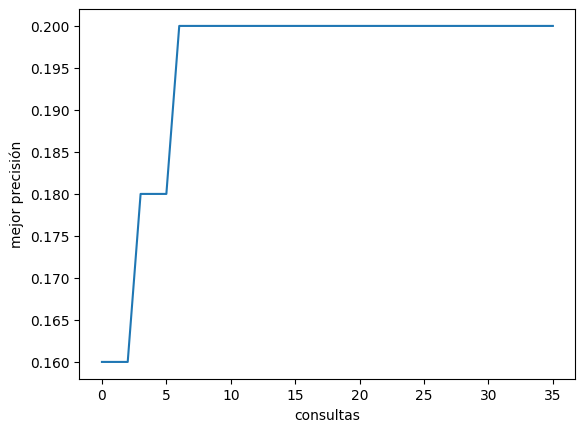

,paso,config,precision,instancias_evaluadas,abandonada_por_poda,mejor_acumulada,segundos
0,1,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1600,100,False,0.16,0.0
1,2,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1400,100,False,0.16,0.0
2,3,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1500,100,False,0.16,0.0
3,4,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1800,100,False,0.18,59.0
4,5,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1600,100,False,0.18,285.1
5,6,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1458,96,True,0.18,266.0
6,7,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.2000,100,False,0.20,282.4
7,8,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1667,96,True,0.20,266.0
8,9,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1562,96,True,0.20,266.4
9,10,"{'cierre': 3, 'formato': 0, 'estilo': 6, 'estr...",0.1042,96,True,0.20,265.4


In [5]:
import random
import time
import pandas as pd
from ayudas import curva

random.seed(0)

# ─────────────────────────────────────────────────────────────────────
#  1. Parámetros del Algoritmo y Presupuesto
# ─────────────────────────────────────────────────────────────────────
INSTANCIAS = busqueda          # 100 instancias de búsqueda curadas
N_TOTAL = len(INSTANCIAS)      # 100
B_CONSULTAS = 36               # Presupuesto en CONFIGURACIONES (~2 horas en T4 a ~207 s/config)
TAM_LOTE = getattr(oraculo, "lote", 16)  # Tamaño de lote del oráculo para batching

# Cota interna en nodo parcial: Heurística (no admisible). Desactivada por defecto.
USAR_PODA_INTERNA_HEURISTICA = False

# ─────────────────────────────────────────────────────────────────────
#  2. Orden de Ranuras y Opciones Derivado de Trazas y Datos Reales
# ─────────────────────────────────────────────────────────────────────
ORDEN_RANURAS = ["cierre", "formato", "estilo", "estrategia", "rol"]

ORDEN_OPCIONES = {
    "cierre":     [3, 6, 2, 7, 5, 4, 1, 0],
    "formato":    [0, 4, 6, 2, 1, 7, 3, 5],
    "estilo":     [6, 2, 0, 3, 4, 1, 5, 7],
    "estrategia": [2, 1, 5, 4, 6, 7, 0, 3],
    "rol":        [5, 2, 3, 0, 1, 4, 6, 7],
}

# ─────────────────────────────────────────────────────────────────────
#  3. Estructuras de Auditoría e Incumbente Inicial
# ─────────────────────────────────────────────────────────────────────
historial = []
tabla_audit = []
stats = {
    "configs_evaluadas": 0,
    "hojas_abandonadas": 0,
    "instancias_ahorradas": 0,
    "tiempo_total": 0.0,
    "estado": "COMPLETA"
}

# El incumbente inicial es la primera hoja evaluada por el propio algoritmo
mejor = (-1.0, None)

# ─────────────────────────────────────────────────────────────────────
#  4. Evaluación por Lotes con Poda por Abandono Temprano
# ─────────────────────────────────────────────────────────────────────
def evaluar_hoja_con_cota(cfg, instancias, incumbente_prec, lote_size=16):
    """
    Evalúa una hoja por lotes aplicando la cota rigurosa por instancia:
    CotaSuperior(k) = (aciertos + n - k) / n.
    Si CotaSuperior(k) <= incumbente_prec, abandona inmediatamente la evaluación.
    """
    n = len(instancias)
    aciertos = 0
    k = 0
    trazas_fallo = []
    abandonada = False

    for i in range(0, n, lote_size):
        lote = instancias[i : i + lote_size]
        r_lote = oraculo.evaluar(cfg, lote, semilla=1)

        aciertos_este_lote = len(lote) - len(r_lote.trazas)
        aciertos += aciertos_este_lote
        k += len(lote)
        trazas_fallo.extend(r_lote.trazas)

        cota_maxima = (aciertos + (n - k)) / n

        # Poda por abandono temprano (solo si ya existe un incumbente válido)
        if incumbente_prec >= 0.0 and cota_maxima <= incumbente_prec and k < n:
            abandonada = True
            break

    precision_reportada = (aciertos / n) if not abandonada else (aciertos / k)
    return precision_reportada, trazas_fallo, k, abandonada, cota_maxima

# ─────────────────────────────────────────────────────────────────────
#  5. Recorrido Backtracking con Control de Presupuesto B
# ─────────────────────────────────────────────────────────────────────
class PresupuestoAgotado(Exception):
    pass

t_inicio_total = time.time()

def backtracking(config_parcial, nivel):
    global mejor

    if stats["configs_evaluadas"] >= B_CONSULTAS:
        stats["estado"] = "TRUNCADA"
        raise PresupuestoAgotado

    if nivel == len(ORDEN_RANURAS):
        cfg_completa = dict(config_parcial, temperatura=0.0)

        t0 = time.time()
        prec_rep, trazas, k_eval, abandonada, cota_max = evaluar_hoja_con_cota(
            cfg_completa, INSTANCIAS, mejor[0], lote_size=TAM_LOTE
        )
        dt = time.time() - t0

        stats["configs_evaluadas"] += 1
        stats["tiempo_total"] += dt

        if abandonada:
            stats["hojas_abandonadas"] += 1
            stats["instancias_ahorradas"] += (N_TOTAL - k_eval)
            historial.append(prec_rep)
            print(f"eval {stats['configs_evaluadas']:2d}/{B_CONSULTAS} | ABANDONADA en {k_eval:2d}/100 inst (cota {cota_max:4.1%} <= mejor {mejor[0]:4.1%}) | {dt:5.1f}s")
        else:
            historial.append(prec_rep)
            if mejor[1] is None or prec_rep > mejor[0]:
                mejor = (prec_rep, cfg_completa)
                print(f"eval {stats['configs_evaluadas']:2d}/{B_CONSULTAS} | NUEVO MEJOR: {prec_rep:5.1%} (100/100 inst) | {dt:5.1f}s | {cfg_completa}")
            else:
                print(f"eval {stats['configs_evaluadas']:2d}/{B_CONSULTAS} | evaluada:    {prec_rep:5.1%} (100/100 inst) | {dt:5.1f}s")

        tabla_audit.append({
            "paso": stats["configs_evaluadas"],
            "config": dict(cfg_completa),
            "precision": round(prec_rep, 4),
            "instancias_evaluadas": k_eval,
            "abandonada_por_poda": abandonada,
            "mejor_acumulada": round(mejor[0], 4) if mejor[0] >= 0 else 0.0,
            "segundos": round(dt, 1)
        })

        if stats["configs_evaluadas"] >= B_CONSULTAS:
            stats["estado"] = "TRUNCADA"
            raise PresupuestoAgotado
        return

    ranura = ORDEN_RANURAS[nivel]
    for opt in ORDEN_OPCIONES[ranura]:
        config_parcial[ranura] = opt
        backtracking(config_parcial, nivel + 1)
        del config_parcial[ranura]

# ─────────────────────────────────────────────────────────────────────
#  6. Ejecución y Reporte Final
# ─────────────────────────────────────────────────────────────────────
print(f"=== INICIANDO BACKTRACKING CON PODA POR ABANDONO TEMPRANO ===")
print(f"Espacio: 32 768 configs | B_CONSULTAS = {B_CONSULTAS} configs | Lote = {TAM_LOTE} inst\n")

try:
    backtracking({}, 0)
except PresupuestoAgotado:
    pass

tiempo_total_real = time.time() - t_inicio_total
df_audit = pd.DataFrame(tabla_audit)

print("\n" + "=" * 65)
print(f"ESTADO DE BÚSQUEDA:                 {stats['estado']}")
if stats["estado"] == "TRUNCADA":
    print("  ⚠ Búsqueda truncada por límite de presupuesto B_CONSULTAS.")
    print("  ⚠ NO hay garantía de optimalidad global (subespacio inexplorado).")
print(f"Configuraciones evaluadas:          {stats['configs_evaluadas']} / {B_CONSULTAS}")
print(f"Hojas abandonadas por poda:         {stats['hojas_abandonadas']}")
print(f"Instancias ahorradas en GPU:        {stats['instancias_ahorradas']} / {stats['configs_evaluadas'] * N_TOTAL}")
print(f"Tiempo total de búsqueda:           {tiempo_total_real / 60:.1f} min ({tiempo_total_real:.1f} s)")
print(f"\nMEJOR CONFIGURACIÓN ENCONTRADA:")
print(f"  Precisión:                        {mejor[0]:.1%}")
print(f"  Configuración:                    {mejor[1]}")
print("=" * 65)

curva(historial)
display(df_audit)

### Leer los fallos

Cada resultado trae sus trazas: mírenlas todas las veces que quieran. `violo` es la **primera** restricción que no pasó (el puntaje es todo-o-nada, no hace falta listar las demás). `salida` es el texto que produjo el modelo.

Si quieren ver el prompt **antes** de generar, `ver_prompt(config, instancia)` en `ayudas` arma el texto exacto que recibiría el modelo.

In [6]:
# Reusa el caché: estas instancias ya se midieron al buscar.
r = oraculo.evaluar(mejor[1], INSTANCIAS, semilla=1)

for t in r.trazas[:3]:
    print("violó:", t["violo"])
    print(t["salida"][:300])
    print("-" * 60)

violó: letters:letter_counting2
<<Answer to Question>>

The answer will cover the question about the best place to go for a good experience. It will not cover any other topics.

The letter o appears 7 times in the response. It is less than 9.

Is there anything else I can help with?
------------------------------------------------------------
violó: punctuation:punctuation_dot
A python function to analyze the progress of a list of projects and provide a summary report is provided below. The function calculates the average completion percentage of all projects, the average completion percentage of high priority projects, and the count of projects that have a completion per
------------------------------------------------------------
violó: last_word:last_word_sent
"study

"SELECT COUNT(DISTINCT FilmID) FROM Films WHERE Genre = 'Documentary' AND PublicationYear = 2021 AND DirectorID IN (SELECT DirectorID FROM Directors WHERE Nationality != 'United States');"

The query calculates the num

### Validar la config elegida

Las instancias de validación no se usaron al buscar. Sirve para ver si la config aguanta instancias nuevas, no para elegir otra — si eligen con la validación, dejan de ser un conjunto de prueba.

Validarlas todas tarda; `n` escoge cuántas medir. La muestra es fija: las mismas n en cada llamada. Además imprime qué restricciones se cayeron más.

In [9]:
# n=30 es una muestra representativa de validación fija
r_val = oraculo.validar(mejor[1], n=None)

print("búsqueda (mejor):", f"{mejor[0]:.1%}")
print("validación:      ", f"{r_val.precision:.1%}")

validando:   0%|          | 0/57 [00:00<?, ?inst/s]

validación: 23.0%  (87 inst)
    7  punctuation:punctuation_dot
    6  last_word:last_word_sent
    5  copy:repeat_phrase
    4  letters:letter_counting
    4  length_constraints:nth_paragraph_first_word
    3  new:copy_span_idx
    2  change_case:capital_word_frequency
    2  first_word:first_word_sent
búsqueda (mejor): 20.0%
validación:       23.0%


### Interpretación Académica de la Validación

> [!IMPORTANT]
> **Qué demuestra la validación:**
> Evalúa si la configuración de prompt encontrada **generaliza ante nuevas instancias** que provienen de la misma distribución estadística de datos pero que no fueron vistas durante la fase de búsqueda.
>
> **Qué NO demuestra la validación:**
> 1. **No garantiza optimalidad global:** Obtener una alta precisión en validación no prueba que la configuración sea la mejor absoluta entre las 32 768 del espacio.
> 2. **No garantiza robustez ante familias nuevas:** La partición de validación comparte las mismas familias de restricciones que el conjunto de búsqueda. No garantiza que el prompt resista familias de verificación totalmente inéditas del conjunto de prueba privado del profesor.

## 5 · La entrega

Un `entrega.json` con el grupo, la config ganadora y la semana. La nota no sale de este notebook: el profesor corre esa config sobre un test privado. Se descarga con `files.download`.

In [8]:
from ayudas import entrega
from google.colab import files

# Grupo 1, semana 3. Se guarda en entrega.json y se descarga.
entrega(grupo="Grupo 1", config=mejor[1], semana=3)
try:
    files.download("entrega.json")
except Exception as e:
    print("Archivo entrega.json guardado en disco local.")

{
 "grupo": "Grupo 1",
 "config": {
  "cierre": 3,
  "formato": 0,
  "estilo": 6,
  "estrategia": 2,
  "rol": 6,
  "temperatura": 0.0
 },
 "semana": 3
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>